# CoordinX — Feature Engineering Pipeline
**PRD Phase 3**: Ekstraksi fitur terstruktur pada tiga level (Post, Akun, Jaringan) untuk dataset `RoySuryo`.

### Arsitektur Fitur:
1. **Post-Level Features**: `body_len`, `n_tags`, `has_url`, `is_reply`, `is_quote`, `relation_type`.
2. **Account-Level Features**: `n_posts`, `post_rate`, `avg_tags`, `avg_body_len`, `follower_ratio`, `active_hours`.
3. **Network-Level Features**: `in_degree`, `out_degree`, `total_degree`, `pagerank`, `component_size`.

### Deliverables:
- `data/features/batch3_posts_with_features.csv`
- `data/features/batch3_account_features.csv`
- `reports/FEATURE_DICTIONARY.md`

## 1. Setup & Data Loading

In [7]:
import os
import re
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
pd.set_option('display.max_columns', None)

# Resolve data path secara adaptif
candidate_paths = [
    '../data/processed/RoySuryo/standardized_data.csv',
    'data/processed/RoySuryo/standardized_data.csv',
    os.path.join(os.getcwd(), 'data/processed/RoySuryo/standardized_data.csv'),
    os.path.join(os.getcwd(), '../data/processed/RoySuryo/standardized_data.csv')
]
DATA_PATH = next((p for p in candidate_paths if os.path.exists(p)), None)
if DATA_PATH is None:
    raise FileNotFoundError("Dataset standardized_data.csv tidak ditemukan.")

df = pd.read_csv(DATA_PATH, dtype={'post_id': 'string', 'account_id': 'string', 'target_account_id': 'string'})
df['date'] = pd.to_datetime(df['date'], utc=True)
print(f"✓ Loaded: {len(df)} posts from {df['account_id'].nunique()} accounts")

✓ Loaded: 1081 posts from 796 accounts


## 2. Post-Level Feature Extraction

In [8]:
# 1. Ekstraksi Hashtags dan Jumlahnya
df['hashtags'] = df['text'].astype(str).str.findall(r'#\w+')
df['n_tags'] = df['hashtags'].str.len()

# 2. Pembersihan Teks (buang mention & URL untuk mengukur panjang narasi asli)
df['body_clean'] = df['text'].astype(str).str.replace(r'https?://\S+', '', regex=True)
df['body_clean'] = df['body_clean'].str.replace(r'@\w+', '', regex=True).str.strip()
df['body_len'] = df['body_clean'].str.len()

# 3. Keberadaan URL Link
df['has_url'] = df['text'].astype(str).str.contains(r'https?://', regex=True).astype(int)

# 4. Metadata Waktu Tanggal
df['date_only'] = df['date'].dt.date

print("=== POST-LEVEL FEATURES SUMMARY ===")
display(df[['n_tags', 'body_len', 'has_url']].describe().round(2))
df[['post_id', 'username', 'n_tags', 'body_len', 'has_url', 'relation_type']].head()

=== POST-LEVEL FEATURES SUMMARY ===


,n_tags,body_len,has_url
count,1081.00,1081.00,1081.00
mean,0.22,165.88,0.26
std,0.86,190.01,0.44
min,0.00,0.00,0.00
25%,0.00,69.00,0.00
50%,0.00,127.00,0.00
75%,0.00,212.00,1.00
max,10.00,2410.00,1.00


,post_id,username,n_tags,body_len,has_url,relation_type
0,2119413607498748059,TVKarl_News,5,271,1,original
1,2119413544428937341,alexdananjaya,0,62,0,reply
2,2119413505329873174,JAnjarrio,0,77,0,reply
3,2119408505925030300,Dokebassi,0,123,0,reply
4,2119408416770973826,bobidasaya,0,223,0,reply


## 3. Account-Level Feature Extraction

In [9]:
# Agregasi Akun
accounts = df.groupby('account_id').agg(
    username=('username', 'first'),
    n_posts=('post_id', 'count'),
    avg_tags=('n_tags', 'mean'),
    avg_body_len=('body_len', 'mean'),
    n_replies=('is_reply', lambda x: (x == True).sum() if x.dtype == bool else (x.astype(str) == 'True').sum()),
    n_quotes=('is_quote', lambda x: (x == True).sum() if x.dtype == bool else (x.astype(str) == 'True').sum()),
    n_originals=('relation_type', lambda x: (x == 'original').sum()),
    first_post=('date', 'min'),
    last_post=('date', 'max'),
    followers=('followers', 'first'),
    following=('following', 'first')
).reset_index()

# Metrik Temporal: Active Hours & Post Rate
accounts['active_hours'] = (accounts['last_post'] - accounts['first_post']).dt.total_seconds() / 3600.0

# PRD 8.2: Akun dengan active_hours == 0 (hanya 1 postingan) dinormalisasi agar post_rate tidak infinite
accounts['post_rate'] = accounts.apply(
    lambda r: round(r['n_posts'] / max(r['active_hours'], 0.1), 2) if r['active_hours'] > 0 else 10.0,
    axis=1
)

# Metrik Profil: Follower Ratio
accounts['followers'] = pd.to_numeric(accounts['followers'], errors='coerce').fillna(0).astype(int)
accounts['following'] = pd.to_numeric(accounts['following'], errors='coerce').fillna(0).astype(int)
accounts['follower_ratio'] = (accounts['followers'] / (accounts['following'] + 1)).round(3)

print(f"✓ Account features extracted for {len(accounts)} accounts")
display(accounts[['n_posts', 'post_rate', 'avg_tags', 'avg_body_len', 'follower_ratio']].describe().round(2))
accounts.head()

✓ Account features extracted for 796 accounts


,n_posts,post_rate,avg_tags,avg_body_len,follower_ratio
count,796.00,796.00,796.00,796.00,796.00
mean,1.36,9.02,0.19,158.57,2487.31
std,1.44,3.96,0.83,188.46,28013.28
min,1.00,0.03,0.00,0.00,0.00
25%,1.00,10.00,0.00,65.00,0.36
50%,1.00,10.00,0.00,117.50,0.85
75%,1.00,10.00,0.00,202.42,1.53
max,29.00,40.00,10.00,2410.00,457853.64


,account_id,username,n_posts,avg_tags,avg_body_len,n_replies,n_quotes,n_originals,first_post,last_post,followers,following,active_hours,post_rate,follower_ratio
0,1003546165105704962,DedynurPalakka,1,0.0,244.0,0,0,1,2026-11-07 03:21:10+00:00,2026-11-07 03:21:10+00:00,11110,7065,0.0,10.0,1.572
1,1005369997777035264,hiimpetrus,1,0.0,62.0,0,0,1,2026-11-06 14:31:14+00:00,2026-11-06 14:31:14+00:00,82,229,0.0,10.0,0.357
2,1008408246,YogiBembeng,1,0.0,279.0,0,1,0,2026-11-07 05:54:36+00:00,2026-11-07 05:54:36+00:00,326,454,0.0,10.0,0.716
3,1013325751,supartodwicahyo,1,0.0,52.0,1,0,0,2026-11-08 06:29:50+00:00,2026-11-08 06:29:50+00:00,200,190,0.0,10.0,1.047
4,1014189004554584064,mantuuulll,1,0.0,41.0,1,0,0,2026-11-08 02:48:29+00:00,2026-11-08 02:48:29+00:00,365,364,0.0,10.0,1.000


## 4. Network-Level Feature Extraction (NetworkX)

In [10]:
# Ekstraksi Edges Interaksi (Reply & Quote)
edges = df[df['relation_type'].isin(['reply', 'quote'])].dropna(subset=['target_account_id']).copy()
edges = edges[edges['account_id'] != edges['target_account_id']] # buang self-loops

# Bangun Directed Network
G = nx.DiGraph()
# Pastikan semua akun di dataset ada sebagai node
G.add_nodes_from(accounts['account_id'].unique())
for _, row in edges.iterrows():
    G.add_edge(str(row['account_id']), str(row['target_account_id']))

# Hitung Metrik Sentralitas Jaringan
in_deg = dict(G.in_degree())
out_deg = dict(G.out_degree())
pagerank_scores = nx.pagerank(G, alpha=0.85)

# Hitung Component Size untuk setiap akun
G_undirected = G.to_undirected()
comp_size_map = {}
for comp in nx.connected_components(G_undirected):
    size = len(comp)
    for node in comp:
        comp_size_map[node] = size

# Gabungkan fitur jaringan ke DataFrame akun
accounts['in_degree'] = accounts['account_id'].map(in_deg).fillna(0).astype(int)
accounts['out_degree'] = accounts['account_id'].map(out_deg).fillna(0).astype(int)
accounts['total_degree'] = accounts['in_degree'] + accounts['out_degree']
accounts['pagerank'] = accounts['account_id'].map(pagerank_scores).fillna(0).round(6)
accounts['component_size'] = accounts['account_id'].map(comp_size_map).fillna(1).astype(int)

print(f"✓ Network features computed: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")
display(accounts[['in_degree', 'out_degree', 'total_degree', 'pagerank', 'component_size']].describe().round(4))
accounts.sort_values(by='total_degree', ascending=False).head(10)

✓ Network features computed: 1054 nodes, 695 edges


,in_degree,out_degree,total_degree,pagerank,component_size
count,796.0000,796.0000,796.0000,796.0000,796.0000
mean,0.4183,0.8731,1.2915,0.0009,102.1809
std,1.7308,1.2620,2.0145,0.0010,147.3853
min,0.0000,0.0000,0.0000,0.0006,1.0000
25%,0.0000,0.0000,1.0000,0.0006,2.0000
50%,0.0000,1.0000,1.0000,0.0006,4.0000
75%,0.0000,1.0000,1.0000,0.0006,323.0000
max,22.0000,25.0000,26.0000,0.0115,323.0000


,account_id,username,n_posts,avg_tags,avg_body_len,n_replies,n_quotes,n_originals,first_post,last_post,followers,following,active_hours,post_rate,follower_ratio,in_degree,out_degree,total_degree,pagerank,component_size
313,1659058096659136513,eka2_suprianto,29,0.0,111.275862,29,0,0,2026-11-06 15:32:34+00:00,2026-11-07 14:51:59+00:00,26,95,23.323611,1.24,0.271,1,25,26,0.001170,323
531,2002820059648212992,olaolelaoo,4,0.0,112.750000,0,0,4,2026-11-06 13:06:50+00:00,2026-11-07 23:09:25+00:00,310,34,34.043056,0.12,8.857,22,0,22,0.010763,323
179,1389107518702374915,suncomeinrain,2,0.0,567.500000,0,0,2,2026-11-05 16:07:15+00:00,2026-11-06 09:13:24+00:00,11678,9620,17.102500,0.12,1.214,22,0,22,0.011224,323
642,3007567602,netizenledger,1,0.0,278.000000,0,0,1,2026-11-07 01:23:26+00:00,2026-11-07 01:23:26+00:00,24244,18212,0.000000,10.00,1.331,18,0,18,0.010310,19
224,1502822366946402304,DokterTifa,1,0.0,1581.000000,0,0,1,2026-11-07 01:07:22+00:00,2026-11-07 01:07:22+00:00,224781,1170,0.000000,10.00,191.956,11,0,11,0.005727,323
515,1979047796809355264,bobidasaya,13,0.0,179.615385,13,0,0,2026-11-06 14:57:56+00:00,2026-11-08 12:35:17+00:00,14,39,45.622500,0.28,0.350,0,11,11,0.000632,323
370,1749698965539553280,regar_op0sisi,3,0.0,390.333333,0,0,3,2026-11-06 01:16:27+00:00,2026-11-07 08:24:17+00:00,25753,3838,31.130556,0.10,6.708,10,0,10,0.003980,323
0,1003546165105704962,DedynurPalakka,1,0.0,244.000000,0,0,1,2026-11-07 03:21:10+00:00,2026-11-07 03:21:10+00:00,11110,7065,0.000000,10.00,1.572,10,0,10,0.005310,323
367,1745265761416056832,indepenSumatera,1,0.0,263.000000,0,0,1,2026-11-05 05:42:14+00:00,2026-11-05 05:42:14+00:00,73415,21656,0.000000,10.00,3.390,9,0,9,0.004624,323
83,121640063,RadioElshinta,1,4.0,1144.000000,0,0,1,2026-11-06 02:01:50+00:00,2026-11-06 02:01:50+00:00,3240504,12,0.000000,10.00,249269.538,9,0,9,0.004463,323


## 5. Visualisasi Fitur & Korelasi

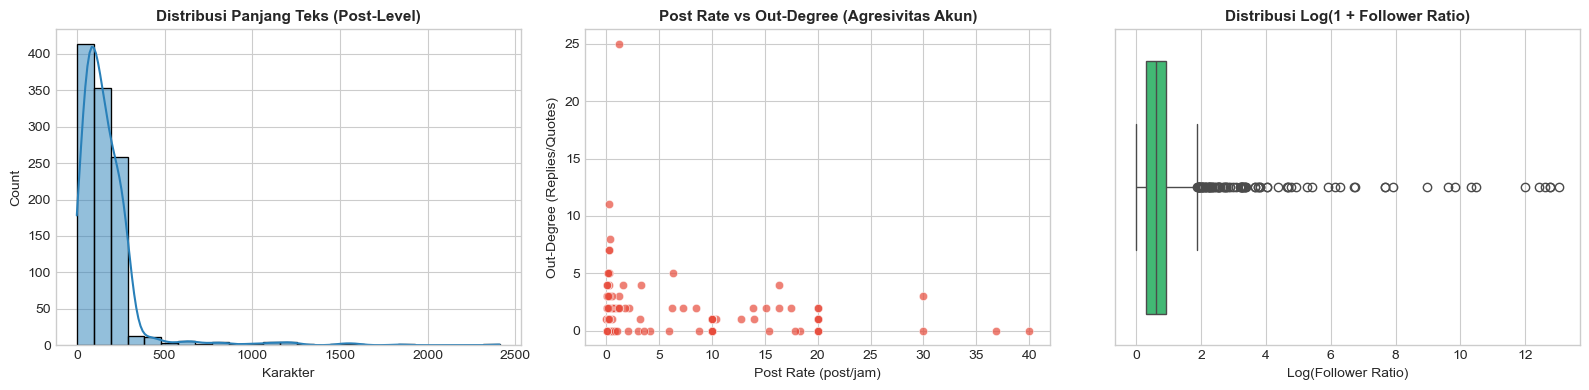

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# 1. Distribusi Body Length
sns.histplot(df['body_len'], bins=25, kde=True, ax=axes[0], color='#2980b9')
axes[0].set_title('Distribusi Panjang Teks (Post-Level)', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Karakter')

# 2. Post Rate vs Out-degree
sns.scatterplot(data=accounts, x='post_rate', y='out_degree', ax=axes[1], color='#e74c3c', alpha=0.7)
axes[1].set_title('Post Rate vs Out-Degree (Agresivitas Akun)', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Post Rate (post/jam)')
axes[1].set_ylabel('Out-Degree (Replies/Quotes)')

# 3. Follower Ratio Distribution (Log Scale)
sns.boxplot(x=np.log1p(accounts['follower_ratio']), ax=axes[2], color='#2ecc71')
axes[2].set_title('Distribusi Log(1 + Follower Ratio)', fontsize=11, fontweight='bold')
axes[2].set_xlabel('Log(Follower Ratio)')

plt.tight_layout()
plt.show()

## 6. Export Dataset Fitur & Feature Dictionary

In [12]:
# Tentukan direktori output (adaptif)
features_dir = Path('../data/features') if os.path.exists('../data') else Path('data/features')
reports_dir = Path('../reports') if os.path.exists('../reports') else Path('reports')
features_dir.mkdir(parents=True, exist_ok=True)
reports_dir.mkdir(parents=True, exist_ok=True)

# Simpan fitur post & akun
posts_out = features_dir / 'batch3_posts_with_features.csv'
accounts_out = features_dir / 'batch3_account_features.csv'

df.to_csv(posts_out, index=False)
accounts.to_csv(accounts_out, index=False)

print(f"✓ Saved: {posts_out} ({len(df)} rows)")
print(f"✓ Saved: {accounts_out} ({len(accounts)} rows)")

# Generate reports/FEATURE_DICTIONARY.md secara otomatis
dict_content = """# COORDINX — FEATURE DICTIONARY
**PRD Phase 3 Deliverable**  
**Dataset:** Batch 3 (`RoySuryo`)  

---

## 1. Post-Level Features (`batch3_posts_with_features.csv`)

| Feature | Tipe Data | Deskripsi | Range / Nilai |
|---|---|---|---|
| `post_id` | String | ID unik postingan X | 19-digit snowflake string |
| `account_id` | String | ID unik akun penulis | 10-19 digit string |
| `body_clean` | String | Teks tweet setelah URL dan mention (@user) dibersihkan | Teks bebas |
| `body_len` | Integer | Jumlah karakter teks narasi bersih | 0 - 300+ |
| `hashtags` | List[String] | Daftar hashtag yang dipakai dalam tweet | Array string |
| `n_tags` | Integer | Jumlah hashtag dalam satu postingan | 0 - 10+ |
| `has_url` | Integer (0/1) | Indikator apakah tweet memuat tautan web luar | 0 atau 1 |
| `relation_type` | String | Jenis hubungan postingan | `original`, `reply`, `quote` |
| `date` | Datetime (UTC) | Waktu publikasi postingan | ISO-8601 UTC |

---

## 2. Account-Level Features (`batch3_account_features.csv`)

| Feature | Tipe Data | Deskripsi | Logika Buzzer |
|---|---|---|---|
| `n_posts` | Integer | Total postingan akun dalam dataset | Akun sangat aktif lebih mencurigakan |
| `active_hours` | Float | Durasi jam antara postingan pertama dan terakhir | Akun burst memiliki durasi jam kecil |
| `post_rate` | Float | Rata-rata postingan per jam aktif | Spammer memiliki post rate tinggi |
| `avg_tags` | Float | Rata-rata jumlah hashtag per tweet akun | Buzzer kampanye memakai banyak hashtag |
| `avg_body_len` | Float | Rata-rata panjang karakter narasi tweet | Deteksi template pendek vs narasi opini |
| `follower_ratio` | Float | Rasio `followers / (following + 1)` | Akun buzzer baru biasanya memiliki rasio rendah |
| `n_replies` | Integer | Jumlah postingan bertipe reply | Mengukur interaktivitas menyerang/membalas |
| `n_quotes` | Integer | Jumlah postingan bertipe quote | Mengukur amplifikasi narasi |
| `n_originals` | Integer | Jumlah postingan mandiri (original) | Inisiator kampanye |

---

## 3. Network-Level Features (`batch3_account_features.csv`)

| Feature | Tipe Data | Deskripsi | Peran Jaringan |
|---|---|---|---|
| `in_degree` | Integer | Berapa kali akun dibalas/dikutip akun lain | Nilai tinggi = Akun target/korban serbuan |
| `out_degree` | Integer | Berapa kali akun membalas/mengutip akun lain | Nilai tinggi = Akun agresor/inisiator interaksi |
| `total_degree` | Integer | Total koneksi langsung interaksi (`in + out`) | Derajat keterlibatan dalam jaringan |
| `pagerank` | Float | Skor otoritas/pengaruh akun dalam graf terarah | Akun sentral dalam klaster percakapan |
| `component_size` | Integer | Ukuran klaster terhubung tempat akun bernaung | Buzzer sering terkumpul dalam klaster besar |
"""

dict_path = reports_dir / 'FEATURE_DICTIONARY.md'
dict_path.write_text(dict_content, encoding='utf-8')
print(f"✓ Generated: {dict_path}")

✓ Saved: ../data/features/batch3_posts_with_features.csv (1081 rows)
✓ Saved: ../data/features/batch3_account_features.csv (796 rows)
✓ Generated: ../reports/FEATURE_DICTIONARY.md
